# Практическая работа 6.1. Подготовка датасета мебели

В notebook скачивается датасет с Kaggle, показывается состав классов и создается подготовленный набор данных `train / validation / test` для дальнейшего обучения модели в PyTorch.


## Импорты


In [1]:
from __future__ import annotations

import os
from pathlib import Path

PRACTICE_DIR = Path.cwd()
CACHE_DIR = PRACTICE_DIR / ".cache"
DATA_DIR = PRACTICE_DIR / ".data"
MPL_CACHE_DIR = CACHE_DIR / "matplotlib"

for directory in (CACHE_DIR, DATA_DIR, MPL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["MPLCONFIGDIR"] = str(MPL_CACHE_DIR)


In [2]:
import random
import shutil
from collections import defaultdict

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

SEED = 42
IMAGE_SIZE = (128, 128)
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)

DATASET_HANDLE = "udaysankarmukherjee/furniture-image-dataset"
SOURCE_DATASET_DIR = DATA_DIR / "furniture-image-dataset"
PREPARED_DATASET_DIR = DATA_DIR / "furniture-image-dataset-prepared"
CLASS_FOLDERS = {
    "almirah": "almirah_dataset",
    "chair": "chair_dataset",
    "fridge": "fridge dataset",
    "table": "table dataset",
    "television": "tv dataset",
}

if not np.isclose(sum(SPLIT_FRACTIONS), 1.0):
    raise ValueError("Сумма долей train, validation и test должна быть равна 1.")

random.seed(SEED)
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")


/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Описание данных

В работе используется `Furniture Image Dataset` с Kaggle. В датасете выбраны пять классов мебели: `almirah`, `chair`, `fridge`, `table`, `television`.


## Загрузка датасета


In [3]:
def load_furniture_dataset(
    dataset_dir: Path,
    dataset_handle: str,
    class_folders: dict[str, str],
) -> tuple[dict[str, list[Path]], list[str]]:
    """
    Скачивает датасет и собирает изображения по папкам классов.

    Parameters
    ----------
    dataset_dir : Path
        Каталог, в который скачивается датасет.
    dataset_handle : str
        Идентификатор датасета Kaggle.
    class_folders : dict[str, str]
        Соответствие между названием класса и папкой внутри датасета.

    Returns
    -------
    tuple[dict[str, list[Path]], list[str]]
        Словарь с путями к изображениям по классам и список названий классов.
    """
    kagglehub.dataset_download(dataset_handle, output_dir=str(dataset_dir))

    class_to_paths: dict[str, list[Path]] = {}
    class_names = list(class_folders.keys())

    for class_name in class_names:
        class_dir = dataset_dir / class_folders[class_name]
        if not class_dir.exists():
            raise FileNotFoundError(f"Не найдена папка класса: {class_dir}")

        image_paths = sorted(class_dir.glob("*.jpeg"))
        if not image_paths:
            raise FileNotFoundError(f"В папке {class_dir} не найдены изображения.")

        class_to_paths[class_name] = image_paths

    return class_to_paths, class_names


In [4]:
class_to_paths, class_names = load_furniture_dataset(
    SOURCE_DATASET_DIR,
    DATASET_HANDLE,
    CLASS_FOLDERS,
)

full_class_counts = {
    class_name: len(class_to_paths[class_name])
    for class_name in class_names
}

print(f"Количество классов: {len(class_names)}")
print(f"Общее количество изображений: {sum(full_class_counts.values())}")


Количество классов: 5
Общее количество изображений: 15000


In [5]:
for class_name, count in full_class_counts.items():
    print(f"{class_name}: {count}")


almirah: 3000
chair: 3000
fridge: 3000
table: 3000
television: 3000


## Подготовка данных

Все изображения каждого класса перемешиваются и делятся на `train`, `validation` и `test` в одинаковой пропорции. После этого данные перепаковываются в формат папок, который удобно читать через `torchvision.datasets.ImageFolder`.


In [6]:
def make_balanced_split(
    class_to_paths: dict[str, list[Path]],
    split_fractions: tuple[float, float, float],
    seed: int,
) -> dict[str, dict[str, list[Path]]]:
    """
    Делит изображения каждого класса на train, validation и test.

    Parameters
    ----------
    class_to_paths : dict[str, list[Path]]
        Пути к изображениям, сгруппированные по классам.
    split_fractions : tuple[float, float, float]
        Доли train, validation и test.
    seed : int
        Значение для воспроизводимого перемешивания.

    Returns
    -------
    dict[str, dict[str, list[Path]]]
        Пути к изображениям по split и по классу.
    """
    train_fraction, validation_fraction, _ = split_fractions
    rng = random.Random(seed)
    split_records = {
        "train": {},
        "validation": {},
        "test": {},
    }

    for class_name, paths in class_to_paths.items():
        shuffled_paths = list(paths)
        rng.shuffle(shuffled_paths)

        train_count = int(len(shuffled_paths) * train_fraction)
        validation_count = int(len(shuffled_paths) * validation_fraction)

        split_records["train"][class_name] = shuffled_paths[:train_count]
        split_records["validation"][class_name] = shuffled_paths[
            train_count:train_count + validation_count
        ]
        split_records["test"][class_name] = shuffled_paths[
            train_count + validation_count:
        ]

    return split_records


In [7]:
split_records = make_balanced_split(
    class_to_paths,
    SPLIT_FRACTIONS,
    SEED,
)

split_class_counts = {
    split_name: {
        class_name: len(paths)
        for class_name, paths in class_records.items()
    }
    for split_name, class_records in split_records.items()
}

split_sizes = {
    split_name: sum(class_counts.values())
    for split_name, class_counts in split_class_counts.items()
}

for split_name, split_size in split_sizes.items():
    print(f"{split_name}: {split_size}")


train: 10500
validation: 2250
test: 2250


## Разбиение датасета


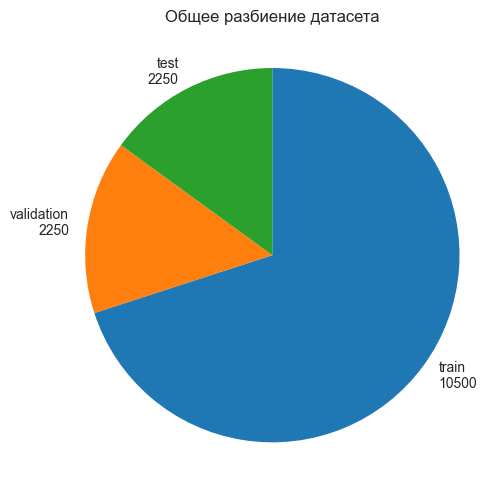

In [8]:
fig, axis = plt.subplots(figsize=(5, 5))
axis.pie(
    list(split_sizes.values()),
    labels=[f"{name}\n{size}" for name, size in split_sizes.items()],
    startangle=90,
    counterclock=False,
)
axis.set_title("Общее разбиение датасета")
axis.axis("equal")
plt.tight_layout()
plt.show()


In [9]:
def plot_class_pie(counts: dict[str, int], title: str) -> None:
    """
    Строит круговую диаграмму распределения изображений по классам.

    Parameters
    ----------
    counts : dict[str, int]
        Количество изображений по классам.
    title : str
        Заголовок диаграммы.
    """
    fig, axis = plt.subplots(figsize=(5, 5))
    axis.pie(
        list(counts.values()),
        labels=[f"{name}\n{count}" for name, count in counts.items()],
        startangle=90,
        counterclock=False,
    )
    axis.set_title(title)
    axis.axis("equal")
    plt.tight_layout()
    plt.show()


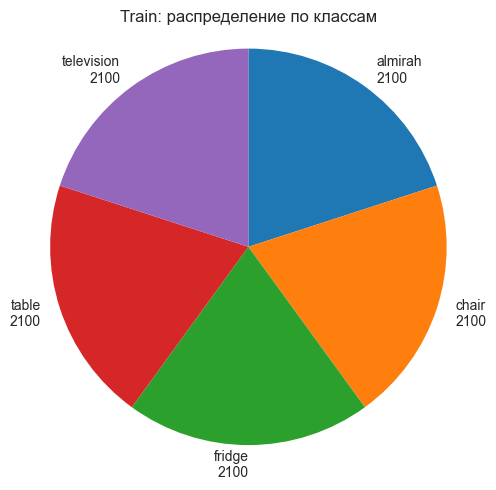

In [10]:
plot_class_pie(split_class_counts["train"], "Train: распределение по классам")


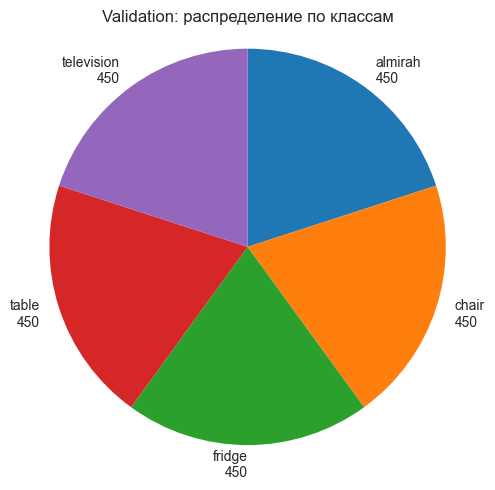

In [11]:
plot_class_pie(split_class_counts["validation"], "Validation: распределение по классам")


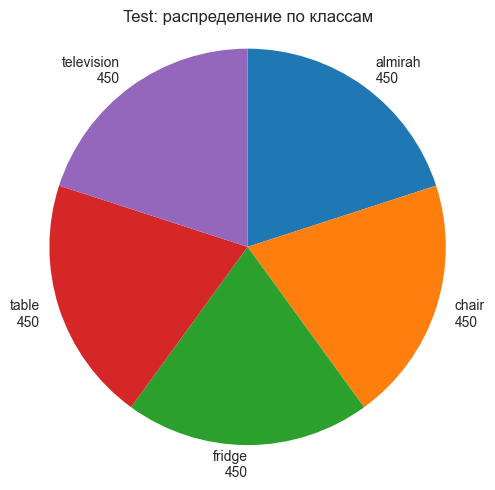

In [12]:
plot_class_pie(split_class_counts["test"], "Test: распределение по классам")


## Превью изображений


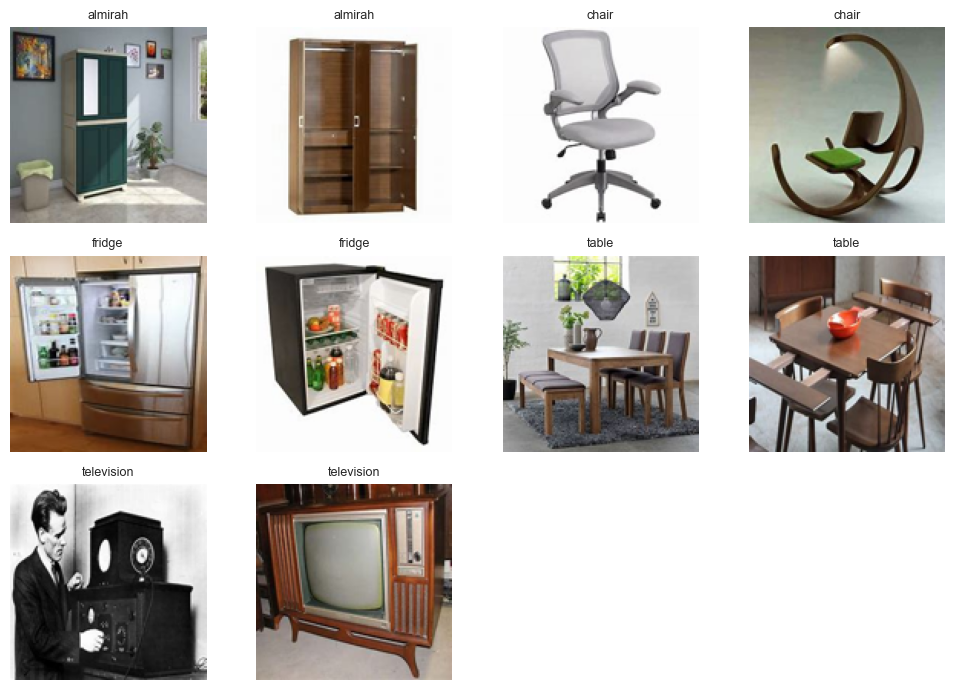

In [13]:
preview_records = []

for class_name in class_names:
    preview_records.extend([
        (class_name, image_path)
        for image_path in split_records["train"][class_name][:2]
    ])

fig, axes = plt.subplots(3, 4, figsize=(10, 7))
axes = np.asarray(axes).reshape(-1)

for axis, (class_name, image_path) in zip(axes, preview_records):
    image = Image.open(image_path).convert("RGB").resize(IMAGE_SIZE)
    axis.imshow(image)
    axis.set_title(class_name, fontsize=9)
    axis.axis("off")

for axis in axes[len(preview_records):]:
    axis.axis("off")

plt.tight_layout()
plt.show()


## Сохранение подготовленного датасета


In [14]:
def create_prepared_dataset(
    prepared_dir: Path,
    split_records: dict[str, dict[str, list[Path]]],
) -> None:
    """
    Копирует изображения в структуру train / validation / test для ImageFolder.

    Parameters
    ----------
    prepared_dir : Path
        Каталог для подготовленного датасета.
    split_records : dict[str, dict[str, list[Path]]]
        Пути к изображениям по split и по классу.
    """
    if prepared_dir.exists():
        shutil.rmtree(prepared_dir)

    for split_name, class_records in split_records.items():
        for class_name, paths in class_records.items():
            target_dir = prepared_dir / split_name / class_name
            target_dir.mkdir(parents=True, exist_ok=True)

            for index, source_path in enumerate(paths, start=1):
                target_name = (
                    f"{class_name}_{source_path.stem}_{index:04d}{source_path.suffix}"
                )
                shutil.copy2(source_path, target_dir / target_name)


In [15]:
create_prepared_dataset(PREPARED_DATASET_DIR, split_records)
print(PREPARED_DATASET_DIR)


/Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 6 - Классификация изображений с использованием PyTorch/.data/furniture-image-dataset-prepared


In [16]:
for split_name in ("train", "validation", "test"):
    print(f"\n{split_name}:")
    for class_name in class_names:
        count = len(list((PREPARED_DATASET_DIR / split_name / class_name).glob("*.jpeg")))
        print(f"  {class_name}: {count}")



train:
  almirah: 2100
  chair: 2100
  fridge: 2100
  table: 2100
  television: 2100

validation:
  almirah: 450
  chair: 450
  fridge: 450
  table: 450
  television: 450

test:
  almirah: 450
  chair: 450
  fridge: 450
  table: 450
  television: 450
